In [1]:
main_dir = '../'

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import sys
import os

sys.path.append(os.path.join(main_dir, 'library'))
from atmocean.inference import NeptuneInference

import warnings
warnings.filterwarnings('ignore')

/Users/davide/anaconda3/envs/fmlenv/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [3]:
model_weights_src = os.path.join(main_dir, 'data/models/neptune-1/neptune.pt')
model_config_src = os.path.join(main_dir, 'data/models/neptune-1/configuration-pretrain.toml')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
res = '1'
ensemble_size = 1
shape = (181, 360)
sealand_mask_3d_src = os.path.join(main_dir, f'data/masks/sealand_{res}_deg/sealand_mask_3d.npy')
sealand_mask_2d_src = os.path.join(main_dir, f'data/masks/sealand_{res}_deg/sealand_mask_2d.npy')
data_dir = os.path.join(main_dir, f'data/datasets/all_{res}_deg')
dtype = torch.float32
# get the sealand mask
sealand_mask_3d = np.load(sealand_mask_3d_src)
sealand_mask_2d = np.load(sealand_mask_2d_src)

In [4]:
neptune = NeptuneInference(
    cfg_src=model_config_src,
    weights_src=model_weights_src,
    device=device,
    dtype=torch.float32,
    sealand_masks=(sealand_mask_3d, sealand_mask_2d),
)

State dict loaded from ../data/models/neptune-1/neptune.pt
Using the custom implementation of load_state_dict()
State dict keys: dict_keys(['phy_to_latent.bias', 'phy_to_latent.weights.10m_u_component_of_wind', 'phy_to_latent.weights.10m_v_component_of_wind', 'phy_to_latent.weights.2m_dewpoint_temperature', 'phy_to_latent.weights.2m_temperature', 'phy_to_latent.weights.geopotential_1000', 'phy_to_latent.weights.geopotential_300', 'phy_to_latent.weights.geopotential_500', 'phy_to_latent.weights.geopotential_600', 'phy_to_latent.weights.geopotential_700', 'phy_to_latent.weights.geopotential_850', 'phy_to_latent.weights.geopotential_925', 'phy_to_latent.weights.mean_sea_level_pressure', 'phy_to_latent.weights.mlotst_oras', 'phy_to_latent.weights.noise', 'phy_to_latent.weights.sea_ice_cover', 'phy_to_latent.weights.sea_surface_temperature', 'phy_to_latent.weights.siconc_oras', 'phy_to_latent.weights.sithick_oras', 'phy_to_latent.weights.so_oras_0', 'phy_to_latent.weights.so_oras_1', 'phy_t

In [5]:
# take two initial conditions for the DL model
ic_dates = (
    '2020-04-10',
    '2020-04-11',
)
# NOTE: data is stored as numpy arrays in this example

In [6]:
x, c, t0 = neptune.load_data(data_dir, ic_dates)
x.shape, c.shape, t0

(torch.Size([1, 110, 2, 181, 360]),
 torch.Size([2, 256, 181, 360]),
 tensor([[101, 102]]))

In [7]:
predictions = neptune.predict(
    initial_conditions = x,
    noise_conditioning = c,
    initial_date       = t0,
)
predictions.keys()

dict_keys(['thetao_oras', 'so_oras', 'uo_oras', 'vo_oras', 'zos_oras', 'mlotst_oras', 'siconc_oras', 'sithick_oras'])

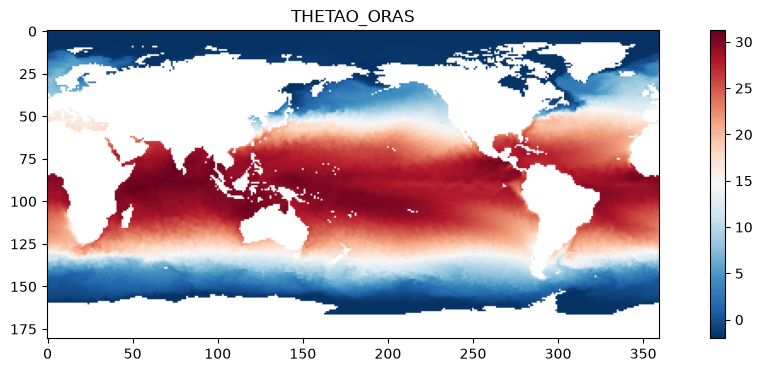

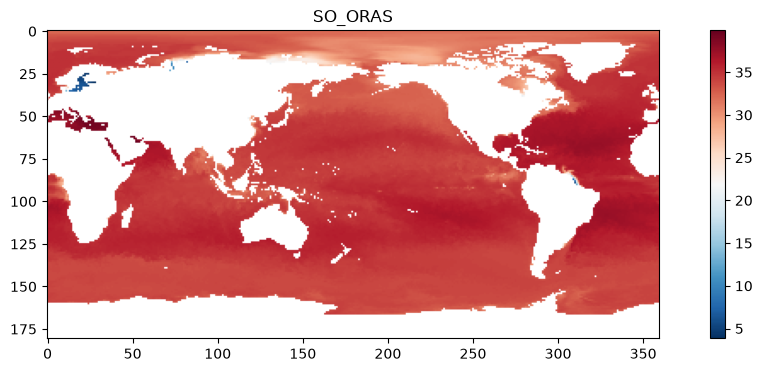

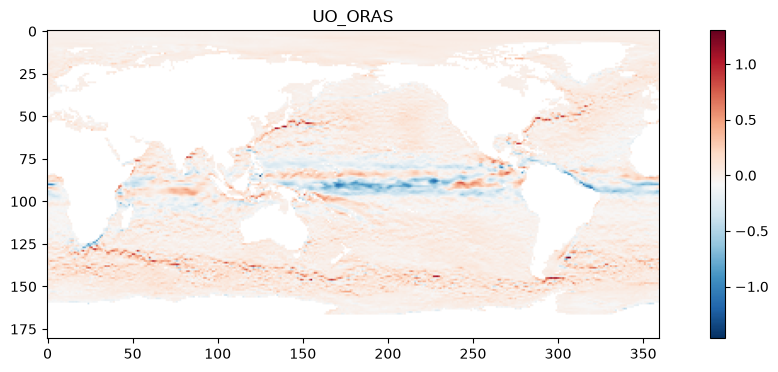

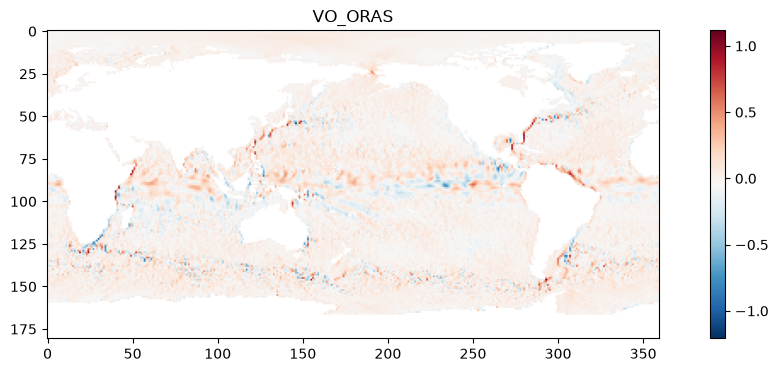

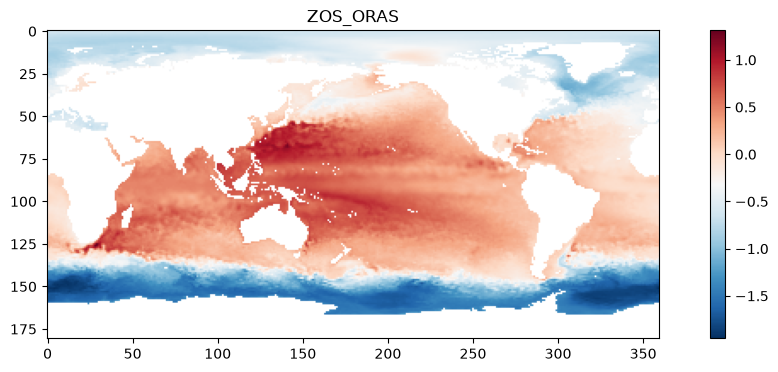

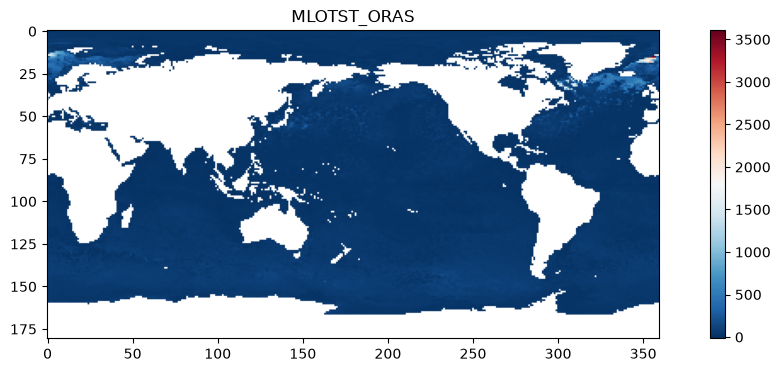

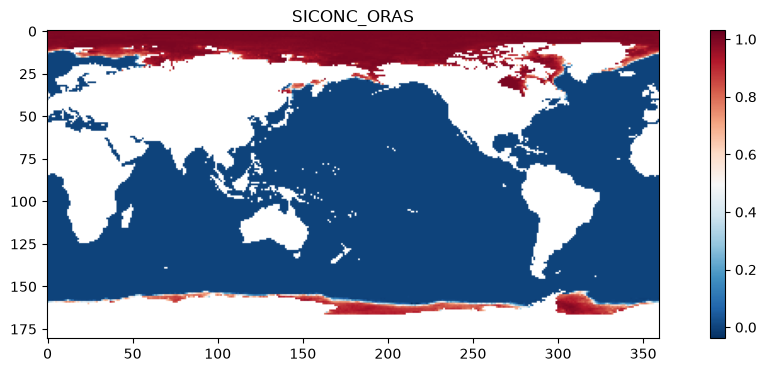

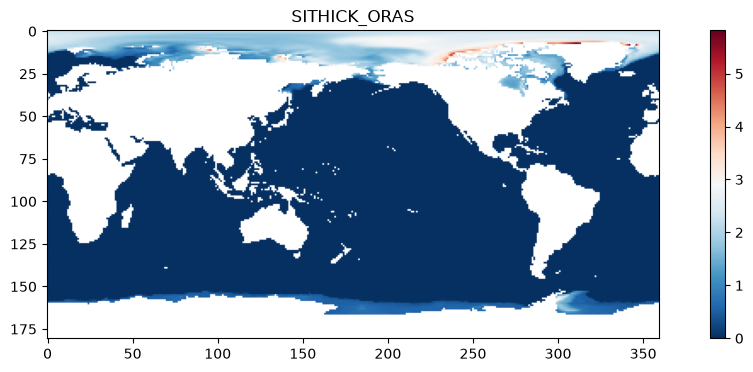

In [8]:
t, d = 0, 0 # timestep and level
for field,data in predictions.items():
    plt.figure(figsize=(13,4))
    plt.title(field.upper())
    try:
        plt.imshow(data[t,d], cmap='RdBu_r')
    except:
        plt.imshow(data[t], cmap='RdBu_r')
    plt.colorbar()
    plt.show()